# 🔎 Análisis exploratorio (EDA) de repuestos — Taller Durand & Jannon

**Pregunta que guía este notebook:**
> *"Hay repuestos para los que 5 unidades es un buen stock porque se usan pocas veces al año, y otros que se usan casi todos los días."*

Esa intuición es correcta y tiene nombre: lo que importa no es **cuántas unidades** hay, sino **cuánto tiempo duran** esas unidades. A eso se le llama **cobertura**:

$$\text{cobertura (meses)} = \frac{\text{unidades en stock}}{\text{unidades que se usan por mes}}$$

5 rodamientos que se usan 10 por mes duran medio mes; 5 horquillas que se usan 1 cada 6 meses duran 2 años y medio.

Para calcular el denominador ("cuánto se usa por mes") necesitamos datos de **consumo**. Vamos a ver qué datos tenemos realmente y hasta dónde nos dejan llegar.

### Cómo usar este notebook
- Ejecutá las celdas **en orden**, de arriba hacia abajo (`Shift + Enter`).
- Cada bloque de código tiene antes una explicación de **qué hace** y **por qué**.
- Los recuadros **🧠 Para pensar** son preguntas para vos: no tienen la respuesta escrita a propósito.
- El notebook **solo lee** la base de datos: no modifica nada.

**Requisitos** (una sola vez, con el entorno virtual activado):
```
pip install pandas matplotlib ipykernel
```

## 1. Preparación

### 1.1 Importar librerías
- `sqlite3`: viene con Python; sirve para conectarse a la base `.sqlite3`.
- `pathlib.Path`: maneja rutas de archivos sin preocuparnos por `\` (Windows) o `/` (Linux).
- `pandas`: la librería de tablas (*DataFrames*). Es como un Excel que se maneja con código.
- `matplotlib`: la librería de gráficos.

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Opciones de visualización: mostrar más columnas y 2 decimales
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

# Colores usados en todos los gráficos (un solo azul en distintas intensidades)
AZUL = "#2a78d6"
AZULES = ["#104281", "#2a78d6", "#86b6ef"]   # oscuro → claro
GRIS = "#898781"

plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

### 1.2 Encontrar la base de datos y conectarse **en modo solo lectura**

El notebook está en `templates/`, pero la base está en `data/`. En vez de escribir la ruta a mano (que cambia de una computadora a otra), la función busca hacia "arriba" la carpeta del proyecto que contiene `data/stock_taller.sqlite3`.

Después nos conectamos con `mode=ro` (*read only*): si por error alguna celda intentara modificar la base, SQLite lo rechazaría. Es una buena práctica cuando solo queremos **explorar**.

In [2]:
def encontrar_raiz_proyecto(inicio: Path) -> Path:
    # Recorre la carpeta actual y sus carpetas "padre" hasta encontrar data/stock_taller.sqlite3
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "data" / "stock_taller.sqlite3").exists():
            return carpeta
    raise FileNotFoundError(
        "No encontré data/stock_taller.sqlite3. ¿Ejecutaste antes apps/inicializar_bd.py?"
    )


RAIZ = encontrar_raiz_proyecto(Path.cwd().resolve())
RUTA_BD = RAIZ / "data" / "stock_taller.sqlite3"

conexion = sqlite3.connect(f"{RUTA_BD.as_uri()}?mode=ro", uri=True)
print("Conectado a:", RUTA_BD)

Conectado a: C:\Users\camil\OneDrive\Documentos\UNER\Ciencia de Datos\POO\Gestor_Stock_Durand_GarciaBode\data\stock_taller.sqlite3


### 1.3 Traer las tablas a pandas

`pd.read_sql(consulta, conexion)` ejecuta una consulta SQL y devuelve el resultado como DataFrame. Traemos las tablas completas porque son chicas (cientos de filas).

In [3]:
tablas = ["repuestos", "movimientos_stock", "marcas", "proveedores",
          "categorias"]

datos = {nombre: pd.read_sql(f"SELECT * FROM {nombre}", conexion) for nombre in tablas}

for nombre, df in datos.items():
    print(f"{nombre:<28} {df.shape[0]:>5} filas × {df.shape[1]} columnas")

repuestos = datos["repuestos"]
movimientos = datos["movimientos_stock"]

repuestos                      192 filas × 11 columnas
movimientos_stock              213 filas × 8 columnas
marcas                          12 filas × 2 columnas
proveedores                      3 filas × 6 columnas
categorias                      18 filas × 3 columnas


Un primer vistazo a cada tabla principal. `.head()` muestra las primeras 5 filas; `.dtypes` muestra el **tipo** de cada columna (número entero, decimal, texto…).

In [4]:
repuestos.head()

,id,codigo,marca_id,categoria_id,especificaciones,unidad_medida,stock_minimo,stock_maximo,punto_reorden,stock_actual,activo
0,1,2110300430,1,1,TR D 44.7 X 3.9 -518 INT- X 6000,unidad,0.00,None,None,1.00,1
1,2,2110300741,1,1,TR D53.7 X 3.75-518/514 EXT- X 6000,unidad,0.00,None,None,1.00,1
2,3,2040350002,1,2,518 FUND C/SB Z 6 1 3/8 C/TCA,unidad,0.00,None,None,6.00,1
3,4,2040352002,1,2,518 P/SOLD TR EXT,unidad,0.00,None,None,3.00,1
4,5,2040352003,1,2,518 P/SOLD TR INT,unidad,0.00,None,None,3.00,1


In [5]:
movimientos.head()

,id,repuesto_id,proveedor_id,fecha,tipo,cantidad,codigo_proveedor_raw,origen
0,1,1,1,2026-01-28,INGRESO,1.00,2110300430,carga_inicial
1,2,2,1,2026-01-28,INGRESO,1.00,2110300741,carga_inicial
2,3,3,1,2026-05-29,INGRESO,6.00,2040350002,carga_inicial
3,4,4,1,2026-07-09,INGRESO,3.00,2040352002,carga_inicial
4,5,5,1,2026-07-09,INGRESO,3.00,2040352003,carga_inicial


In [6]:
movimientos.dtypes

id                        int64
repuesto_id               int64
proveedor_id              int64
fecha                       str
tipo                        str
cantidad                float64
codigo_proveedor_raw        str
origen                      str
dtype: object

👀 La columna `fecha` aparece como texto (`object` o `str`, según la versión de pandas), no como fecha. Para poder restar fechas o agruparlas por mes hay que **convertirla**. Lo hacemos en la sección 3.

## 2. Calidad de los datos: ¿qué tenemos y qué falta?

Antes de calcular nada, conviene revisar los datos. Como dice la clase *"Cuestiones sobre el manejo de datos"*: **que el programa ejecute correctamente no garantiza que el resultado sea correcto**.

### 2.1 Valores faltantes en `repuestos`
`isna()` marca con `True` cada celda vacía (`NULL` en la base, `NaN`/`None` en pandas). Sumando por columna sabemos cuántas faltan.

In [7]:
faltantes = pd.DataFrame({
    "vacíos": repuestos.isna().sum(),
    "% vacíos": repuestos.isna().mean() * 100,
})
faltantes

,vacíos,% vacíos
id,0,0.00
codigo,0,0.00
marca_id,0,0.00
categoria_id,0,0.00
especificaciones,174,90.62
unidad_medida,0,0.00
stock_minimo,0,0.00
stock_maximo,192,100.00
punto_reorden,192,100.00
stock_actual,0,0.00


### 2.2 Chequeos de contenido
Algunos datos no están "vacíos" pero tampoco tienen información útil (por ejemplo, `stock_minimo = 0` en todos). Armamos una tabla con chequeos puntuales.

In [8]:
chequeos = pd.Series({
    "Repuestos totales": len(repuestos),
    "Categorías cargadas en la tabla categorias": len(datos["categorias"]),
    "Repuestos sin categoría": repuestos["categoria_id"].isna().sum(),
    "Repuestos sin especificaciones": repuestos["especificaciones"].isna().sum(),
    "Repuestos sin punto de reorden": repuestos["punto_reorden"].isna().sum(),
    "Repuestos con stock_minimo = 0": (repuestos["stock_minimo"] == 0).sum(),
    "Unidades de medida distintas": repuestos["unidad_medida"].nunique(),
}, name="cantidad")
chequeos.to_frame()

,cantidad
Repuestos totales,192
Categorías cargadas en la tabla categorias,18
Repuestos sin categoría,0
Repuestos sin especificaciones,174
Repuestos sin punto de reorden,192
Repuestos con stock_minimo = 0,192
Unidades de medida distintas,1


In [9]:
# ¿Qué tipos de movimiento hay y de dónde vienen?
pd.crosstab(movimientos["tipo"], movimientos["origen"], margins=True, margins_name="Total")

origen,carga_inicial,Total
tipo,,
INGRESO,213,213
Total,213,213


⚠️ **Hallazgo clave:** todos los movimientos son de tipo **INGRESO** (compras) y vienen de la **carga inicial**. No hay **EGRESOS** (consumo real del taller).

Eso significa que **no podemos medir directamente cuánto se usa cada repuesto**. Lo que sí podemos medir es **cuánto y cada cuánto se compra**. En el resto del notebook vamos a usar la compra como **aproximación** (*proxy*) del uso, bajo este supuesto:

> **Supuesto:** a largo plazo, lo que el taller compra es aproximadamente lo que consume (si no, el stock crecería sin parar).

Es un supuesto razonable para empezar, pero hay que decirlo siempre que mostremos un resultado.

### 2.3 Cantidades con decimales
Todos los repuestos dicen `unidad_medida = "unidad"`. Pero si una cantidad tiene decimales, probablemente no se mida en unidades. `% 1` es el **resto** de dividir por 1: si es distinto de 0, el número tiene decimales.

In [10]:
con_decimales = movimientos[movimientos["cantidad"] % 1 != 0]
con_decimales.merge(repuestos[["id", "codigo"]],
                    left_on="repuesto_id", right_on="id", suffixes=("", "_rep"))[
    ["repuesto_id", "codigo", "fecha", "cantidad"]
]

,repuesto_id,codigo,fecha,cantidad
0,66,ASA 80/1 H -REF,2026-02-27,6.10
1,124,ASA 60/1 H -REF,2026-05-04,3.05
2,125,ASA 60/1,2026-05-04,6.10
3,124,ASA 60/1 H -REF,2026-06-12,6.10


🧠 **Para pensar:** son cadenas. ¿En qué unidad creés que viene la cantidad 3,05 o 6,10? (Pista: buscá cuánto mide un tramo estándar de cadena de rodillos). ¿Cómo debería quedar registrado en `unidad_medida`?

### 2.4 Posibles duplicados
Si un mismo repuesto aparece **dos veces el mismo día**, puede ser que:
1. realmente se compraron en dos renglones distintos del remito, o
2. dos repuestos **diferentes** se unificaron por error durante la limpieza.

`groupby([...]).size()` cuenta cuántas filas hay por cada combinación repuesto + fecha.

In [11]:
por_dia = movimientos.groupby(["repuesto_id", "fecha"]).size()
repetidos = por_dia[por_dia > 1].rename("líneas el mismo día").reset_index()
repetidos.merge(repuestos[["id", "codigo"]],
                left_on="repuesto_id", right_on="id").drop(columns="id")

,repuesto_id,fecha,líneas el mismo día,codigo


🧠 **Para pensar:** con el código completo como identificador, las variantes que antes se unían (horquilla Z21/Z6, REP KIT radial/axial) ya son repuestos distintos, así que esta tabla debería salir **vacía**. Si aparece algo, ¿es una compra repetida en el mismo remito o un error de carga?

## 3. Armar una tabla de análisis

Los movimientos solo tienen `repuesto_id` (un número). Para leer los resultados necesitamos un **nombre entendible**. Un repuesto se identifica por **marca + código** (por ejemplo `ZKL` + `6204 2RS`) y pertenece a una **categoría** (RODAMIENTO, RETEN, HORQUILLA…).

Vamos a:
1. Unir (`merge`) movimientos con repuestos, marcas, categorías y proveedores. Es lo mismo que un `JOIN` en SQL.
2. Crear una **etiqueta** legible: `categoría · código · marca`.
3. Convertir `fecha` de texto a fecha real con `pd.to_datetime`.

In [12]:
marcas = datos["marcas"].rename(columns={"id": "marca_id", "nombre": "marca"})
proveedores = datos["proveedores"].rename(columns={"id": "proveedor_id", "nombre": "proveedor"})

categorias = datos["categorias"].rename(columns={"id": "categoria_id", "nombre": "categoria"})

catalogo = (repuestos
            .rename(columns={"id": "repuesto_id"})
            .merge(marcas, on="marca_id", how="left")
            .merge(categorias[["categoria_id", "categoria"]], on="categoria_id", how="left"))

catalogo["etiqueta"] = catalogo["categoria"] + " · " + catalogo["codigo"] + " · " + catalogo["marca"]

movs = (movimientos
        .merge(catalogo[["repuesto_id", "etiqueta", "categoria", "marca", "stock_actual"]],
               on="repuesto_id", how="left")
        .merge(proveedores[["proveedor_id", "proveedor"]], on="proveedor_id", how="left"))

movs["fecha"] = pd.to_datetime(movs["fecha"])
movs["mes"] = movs["fecha"].dt.to_period("M")

movs[["fecha", "etiqueta", "categoria", "cantidad", "proveedor"]].head(8)

,fecha,etiqueta,categoria,cantidad,proveedor
0,2026-01-28,TUBO · 2110300430 · Produmat,TUBO,1.00,Produmat S.A.
1,2026-01-28,TUBO · 2110300741 · Produmat,TUBO,1.00,Produmat S.A.
2,2026-05-29,HORQUILLA · 2040350002 · Produmat,HORQUILLA,6.00,Produmat S.A.
3,2026-07-09,HORQUILLA · 2040352002 · Produmat,HORQUILLA,3.00,Produmat S.A.
4,2026-07-09,HORQUILLA · 2040352003 · Produmat,HORQUILLA,3.00,Produmat S.A.
5,2026-02-02,HORQUILLA · H-8025/1 / HF1800300000010 · ED-MA,HORQUILLA,2.00,Metalúrgica ED-MA S.R.L.
6,2026-02-02,HORQUILLA · H-8025 / HF1800300000010 · ED-MA,HORQUILLA,2.00,Metalúrgica ED-MA S.R.L.
7,2026-02-02,HORQUILLA · H-4008 / HF1400600000050 · ED-MA,HORQUILLA,3.00,Metalúrgica ED-MA S.R.L.


In [13]:
INICIO, FIN = movs["fecha"].min(), movs["fecha"].max()
MESES_OBSERVADOS = (FIN - INICIO).days / 30.44   # 30,44 = días promedio de un mes

print(f"Período con datos: {INICIO:%d/%m/%Y} → {FIN:%d/%m/%Y}")
print(f"Son {MESES_OBSERVADOS:.1f} meses")

Período con datos: 05/01/2026 → 05/08/2026
Son 7.0 meses


🧠 **Para pensar:** son unos 7 meses. Si un repuesto se usa **2 veces por año**, ¿cuántas compras esperarías ver en este período? ¿Alcanza para "ver" su ritmo?

## 4. Panorama general de las compras

### 4.1 ¿Cuánto se compra cada mes?
Agrupamos por mes y contamos dos cosas distintas:
- **líneas de compra**: cuántos renglones de remito (cuántas veces se compró *algo*);
- **unidades**: la suma de las cantidades.

Van en **dos gráficos separados** porque miden cosas con escalas diferentes (no conviene mezclarlas en un mismo eje).

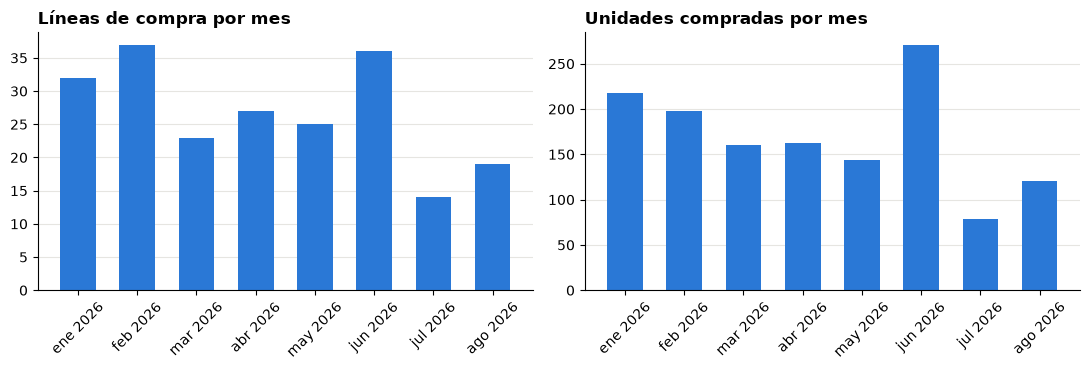

,lineas,unidades
ene 2026,32,218.00
feb 2026,37,198.10
mar 2026,23,160.00
abr 2026,27,163.00
may 2026,25,144.15
jun 2026,36,271.10
jul 2026,14,79.00
ago 2026,19,121.00


In [14]:
por_mes = movs.groupby("mes").agg(lineas=("id", "count"), unidades=("cantidad", "sum"))
MESES_ES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
por_mes.index = [f"{MESES_ES[p.month - 1]} {p.year}" for p in por_mes.index]

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].bar(por_mes.index, por_mes["lineas"], color=AZUL, width=0.6)
ejes[0].set_title("Líneas de compra por mes")
ejes[1].bar(por_mes.index, por_mes["unidades"], color=AZUL, width=0.6)
ejes[1].set_title("Unidades compradas por mes")
for ax in ejes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

por_mes

### 4.2 ¿Cuántas unidades se compran por vez?
`describe()` resume una columna numérica:
- **mean** = promedio; **50%** = mediana (el valor del medio si ordenamos todo);
- **25% / 75%** = cuartiles: el 25% de las compras está por debajo del primero, el 75% por debajo del segundo.

Si el promedio es bastante mayor que la mediana, hay unas pocas compras grandes que "tiran" el promedio para arriba.

In [15]:
movs["cantidad"].describe()

count   213.00
mean      6.36
std       4.83
min       1.00
25%       3.00
50%       5.00
75%      10.00
max      30.00
Name: cantidad, dtype: float64

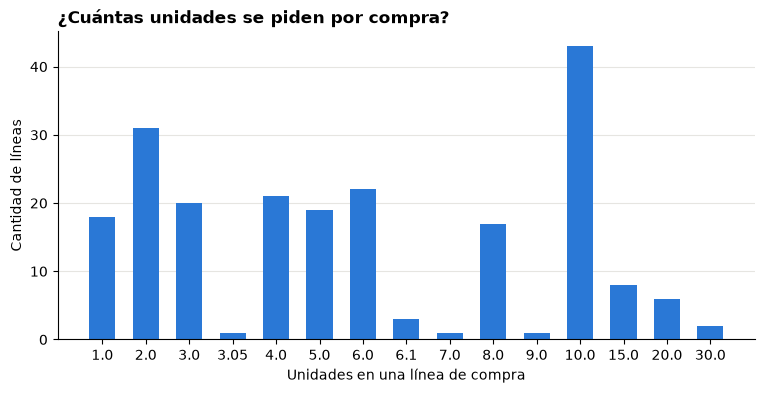

In [16]:
frecuencia_cantidades = movs["cantidad"].round(2).value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(frecuencia_cantidades.index.astype(str), frecuencia_cantidades.values, color=AZUL, width=0.6)
ax.set_title("¿Cuántas unidades se piden por compra?")
ax.set_xlabel("Unidades en una línea de compra")
ax.set_ylabel("Cantidad de líneas")
ax.grid(axis="x", visible=False)
plt.show()

🧠 **Para pensar:** ¿ves números "redondos" que se repiten mucho (10, 2, 6…)? Eso suele indicar **tamaños de pedido habituales** o presentaciones del proveedor, más que el consumo exacto. ¿Qué te dice eso sobre usar la compra como reflejo del uso?

## 5. Métricas por repuesto

Ahora pasamos de "una fila por compra" a "**una fila por repuesto**". Para cada uno calculamos:

| Métrica | Qué significa |
|---|---|
| `n_compras` | En cuántos **días distintos** se compró (usamos días distintos para que dos renglones del mismo remito cuenten como una sola compra) |
| `unidades` | Total de unidades compradas en el período |
| `primera`, `ultima` | Fecha de la primera y de la última compra |
| `dias_entre_compras` | Promedio de días entre una compra y la siguiente (solo si hay 2 o más compras) |
| `uso_mensual_estimado` | `unidades / meses observados` → **la aproximación del consumo** |
| `meses_que_duran_5` | `5 / uso_mensual_estimado` → **tu pregunta**: ¿cuánto me duran 5 unidades? |

In [17]:
por_rep = (movs.groupby(["repuesto_id", "etiqueta", "categoria"])
           .agg(n_compras=("fecha", "nunique"),
                unidades=("cantidad", "sum"),
                primera=("fecha", "min"),
                ultima=("fecha", "max"),
                stock_actual=("stock_actual", "first"))
           .reset_index())

# Días entre compras: solo tiene sentido con 2 o más compras (con 1 compra no hay "entre")
dias_totales = (por_rep["ultima"] - por_rep["primera"]).dt.days
por_rep["dias_entre_compras"] = (dias_totales / (por_rep["n_compras"] - 1)).where(por_rep["n_compras"] > 1)

por_rep["uso_mensual_estimado"] = por_rep["unidades"] / MESES_OBSERVADOS
por_rep["meses_que_duran_5"] = 5 / por_rep["uso_mensual_estimado"]

por_rep.sort_values("unidades", ascending=False).head(10)

,repuesto_id,etiqueta,categoria,n_compras,unidades,primera,ultima,stock_actual,dias_entre_compras,uso_mensual_estimado,meses_que_duran_5
52,53,RODAMIENTO · 6204 2RS · ZKL,RODAMIENTO,4,55.00,2026-02-13,2026-08-05,55.00,57.67,7.90,0.63
45,46,RODAMIENTO · 6203 2RS · ZKL,RODAMIENTO,3,55.00,2026-02-04,2026-06-30,55.00,73.00,7.90,0.63
64,65,RODAMIENTO · 6202 2RS · ZKL,RODAMIENTO,3,40.00,2026-01-05,2026-06-30,40.00,88.00,5.74,0.87
34,35,RETEN · 5339 LX · SAV,RETEN,1,30.00,2026-01-21,2026-01-21,30.00,NaN,4.31,1.16
80,81,RODAMIENTO · 6205-C-2HRS -C3 · FAG,RODAMIENTO,2,30.00,2026-03-18,2026-07-23,30.00,127.00,4.31,1.16
178,179,RETEN · 5189 LX · SAV,RETEN,1,30.00,2026-08-05,2026-08-05,30.00,NaN,4.31,1.16
71,72,RODAMIENTO · 627 2RSR · ZKL,RODAMIENTO,1,20.00,2026-03-12,2026-03-12,20.00,NaN,2.87,1.74
41,42,RETEN · 5195 LX · SAV,RETEN,2,20.00,2026-02-04,2026-05-04,20.00,89.00,2.87,1.74
190,191,RETEN · 5130 LX · SAV,RETEN,1,20.00,2026-01-05,2026-01-05,20.00,NaN,2.87,1.74
158,159,RODAMIENTO · 6208 2RS · ZKL,RODAMIENTO,2,20.00,2026-01-05,2026-06-30,20.00,176.00,2.87,1.74


### 5.1 ¿Cuántas veces se compró cada repuesto?

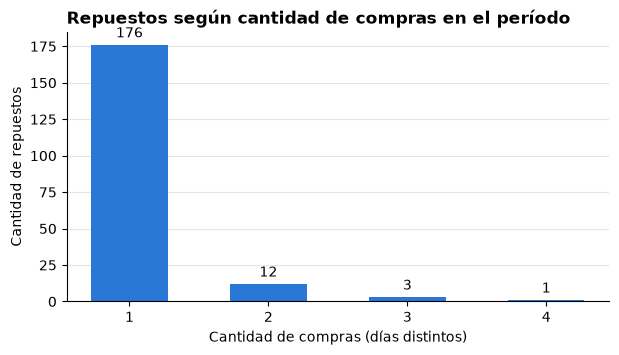

92% de los repuestos se compró una sola vez.


In [18]:
distribucion_compras = por_rep["n_compras"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.bar(distribucion_compras.index.astype(str), distribucion_compras.values, color=AZUL, width=0.55)
ax.bar_label(barras, padding=3)
ax.set_title("Repuestos según cantidad de compras en el período")
ax.set_xlabel("Cantidad de compras (días distintos)")
ax.set_ylabel("Cantidad de repuestos")
ax.grid(axis="x", visible=False)
plt.show()

print(f"{(por_rep['n_compras'] == 1).mean():.0%} de los repuestos se compró una sola vez.")

⚠️ La gran mayoría de los repuestos aparece **una sola vez**. Con un solo dato no se puede calcular un ritmo: no sabemos si ese repuesto se usa una vez por año o si se compró mucho de una vez y todavía queda.

Por eso, en todo lo que sigue, la estimación es **mucho más confiable para los repuestos con 3 o más compras** que para los de una sola compra.

### 5.2 ¿Qué tan distinto es el uso entre repuestos?
Este gráfico responde directamente a tu intuición. Usamos una **escala logarítmica** en el eje horizontal: cada marca vale **10 veces** más que la anterior (0,1 → 1 → 10). Sirve cuando los valores van de muy chicos a muy grandes; en escala normal, los repuestos de poco uso quedarían todos apretados contra el cero.

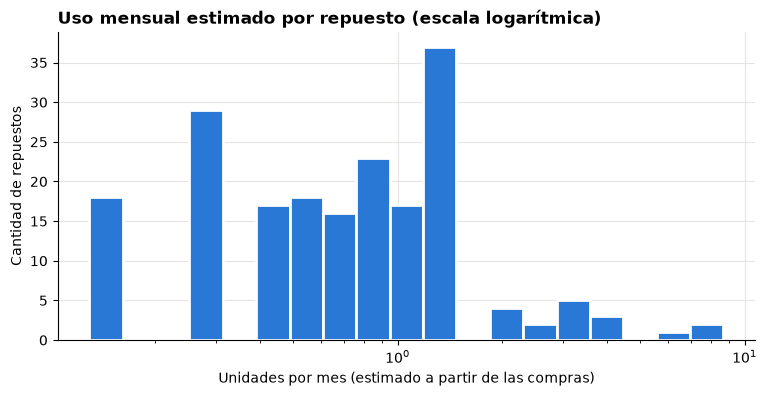

count   192.00
mean      1.01
std       1.08
min       0.14
25%       0.43
50%       0.72
75%       1.44
max       7.90
Name: uso_mensual_estimado, dtype: float64

In [19]:
import numpy as np

fig, ax = plt.subplots()
bordes = np.logspace(np.log10(por_rep["uso_mensual_estimado"].min() * 0.9),
                     np.log10(por_rep["uso_mensual_estimado"].max() * 1.1), 20)
ax.hist(por_rep["uso_mensual_estimado"], bins=bordes, color=AZUL, edgecolor="white", linewidth=2)
ax.set_xscale("log")
ax.set_title("Uso mensual estimado por repuesto (escala logarítmica)")
ax.set_xlabel("Unidades por mes (estimado a partir de las compras)")
ax.set_ylabel("Cantidad de repuestos")
plt.show()

por_rep["uso_mensual_estimado"].describe()

### 5.3 ¿Cuánto me duran 5 unidades?
Comparamos los 10 repuestos de **mayor** uso estimado con los 10 de **menor** uso.

In [20]:
columnas = ["etiqueta", "n_compras", "unidades", "uso_mensual_estimado", "meses_que_duran_5"]
ordenado = por_rep.sort_values("uso_mensual_estimado", ascending=False)

print("🔺 MAYOR uso estimado")
display(ordenado[columnas].head(10))
print("🔻 MENOR uso estimado")
display(ordenado[columnas].tail(10))

🔺 MAYOR uso estimado


,etiqueta,n_compras,unidades,uso_mensual_estimado,meses_que_duran_5
52,RODAMIENTO · 6204 2RS · ZKL,4,55.00,7.90,0.63
45,RODAMIENTO · 6203 2RS · ZKL,3,55.00,7.90,0.63
64,RODAMIENTO · 6202 2RS · ZKL,3,40.00,5.74,0.87
34,RETEN · 5339 LX · SAV,1,30.00,4.31,1.16
80,RODAMIENTO · 6205-C-2HRS -C3 · FAG,2,30.00,4.31,1.16
178,RETEN · 5189 LX · SAV,1,30.00,4.31,1.16
71,RODAMIENTO · 627 2RSR · ZKL,1,20.00,2.87,1.74
41,RETEN · 5195 LX · SAV,2,20.00,2.87,1.74
190,RETEN · 5130 LX · SAV,1,20.00,2.87,1.74
158,RODAMIENTO · 6208 2RS · ZKL,2,20.00,2.87,1.74


🔻 MENOR uso estimado


,etiqueta,n_compras,unidades,uso_mensual_estimado,meses_que_duran_5
26,RODAMIENTO · 32218 -A · ZKL,1,1.00,0.14,34.82
77,RODAMIENTO · 88506 /2AS · NTN,1,1.00,0.14,34.82
115,RODAMIENTO · 20310 -TVP-C3 · FAG,1,1.00,0.14,34.82
119,J. DE AGUJAS · K 55X60X20 · GKL,1,1.00,0.14,34.82
103,ANILLO SEEGER · IR-040 X 25 DIN 472 · GKL,1,1.00,0.14,34.82
108,ANILLO SEEGER · ER-045 X 25 DIN 471 · GKL,1,1.00,0.14,34.82
139,RODAMIENTO · 4T- 33210 · NTN,1,1.00,0.14,34.82
172,RODAMIENTO · 4T-JM 511946/JM511910 · NTN,1,1.00,0.14,34.82
170,RODAMIENTO · 32008 -AX · ZKL,1,1.00,0.14,34.82
171,RODAMIENTO · 4T- 3877/3820 · NTN,1,1.00,0.14,34.82


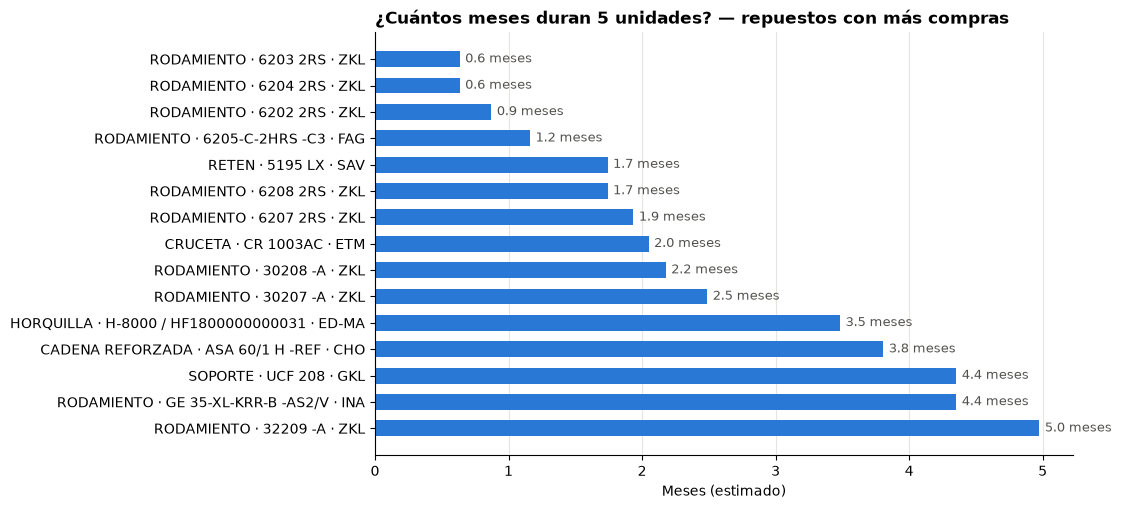

In [21]:
# Gráfico: los 15 repuestos con más compras (los más confiables)
top = (por_rep.sort_values(["n_compras", "unidades"], ascending=False).head(15)
       .sort_values("meses_que_duran_5", ascending=False))   # el que menos dura queda arriba

fig, ax = plt.subplots(figsize=(9, 5.5))
barras = ax.barh(top["etiqueta"], top["meses_que_duran_5"], color=AZUL, height=0.6)
ax.bar_label(barras, fmt="%.1f meses", padding=4, fontsize=9, color="#52514e")
ax.set_title("¿Cuántos meses duran 5 unidades? — repuestos con más compras")
ax.set_xlabel("Meses (estimado)")
ax.grid(axis="y", visible=False)
plt.show()

🧠 **Para pensar:** si el taller tuviera **5 unidades de cada repuesto**, ¿para cuáles sería mucho y para cuáles poco? ¿Qué pasaría si además el proveedor tarda 15 días en entregar?

## 6. Agrupar repuestos según cómo se comportan

Con 189 repuestos no se puede decidir el stock de cada uno "a ojo". Lo habitual es **agruparlos** y definir reglas por grupo. Usamos dos criterios clásicos de gestión de inventario.

### 6.1 Por frecuencia de compra

In [22]:
def clasificar_frecuencia(n):
    if n >= 3:
        return "Alta (3+ compras)"
    if n == 2:
        return "Media (2 compras)"
    return "Baja (1 compra)"


orden_frecuencia = ["Alta (3+ compras)", "Media (2 compras)", "Baja (1 compra)"]
por_rep["frecuencia"] = pd.Categorical(por_rep["n_compras"].apply(clasificar_frecuencia),
                                       categories=orden_frecuencia, ordered=True)
por_rep["frecuencia"].value_counts().sort_index().to_frame("repuestos")

,repuestos
frecuencia,
Alta (3+ compras),4
Media (2 compras),12
Baja (1 compra),176


### 6.2 Análisis ABC (principio de Pareto)
La idea: **pocos repuestos concentran la mayor parte del movimiento**. Se ordenan de mayor a menor y se acumula el porcentaje:
- **A**: los que juntos suman el primer **80%** de las unidades → los más importantes de controlar.
- **B**: los que llevan del 80% al **95%**.
- **C**: el resto (muchos repuestos, poco movimiento).

> Normalmente el ABC se hace con el **valor en pesos** (unidades × precio). Como no tenemos precios, lo hacemos con **unidades**. Un rodamiento barato y una horquilla cara pesan igual acá: tenelo en cuenta.

In [23]:
abc = por_rep.sort_values("unidades", ascending=False).reset_index(drop=True)
abc["% acumulado unidades"] = abc["unidades"].cumsum() / abc["unidades"].sum() * 100
abc["% acumulado repuestos"] = (abc.index + 1) / len(abc) * 100


def clase_abc(porcentaje_acumulado):
    if porcentaje_acumulado <= 80:
        return "A"
    if porcentaje_acumulado <= 95:
        return "B"
    return "C"


abc["clase_abc"] = abc["% acumulado unidades"].apply(clase_abc)
por_rep = por_rep.merge(abc[["repuesto_id", "clase_abc"]], on="repuesto_id")

resumen_abc = abc.groupby("clase_abc").agg(repuestos=("repuesto_id", "count"),
                                           unidades=("unidades", "sum"))
resumen_abc["% repuestos"] = resumen_abc["repuestos"] / resumen_abc["repuestos"].sum() * 100
resumen_abc["% unidades"] = resumen_abc["unidades"] / resumen_abc["unidades"].sum() * 100
resumen_abc

,repuestos,unidades,% repuestos,% unidades
clase_abc,,,,
A,95,"1,080.35",49.48,79.77
B,54,206.00,28.12,15.21
C,43,68.00,22.40,5.02


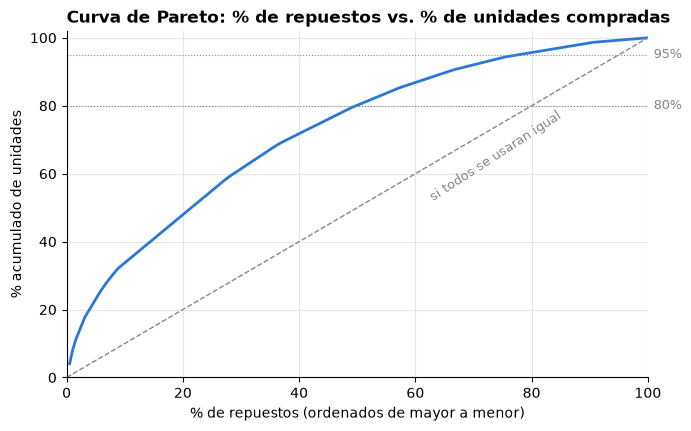

In [24]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(abc["% acumulado repuestos"], abc["% acumulado unidades"], color=AZUL, linewidth=2)
ax.plot([0, 100], [0, 100], color=GRIS, linewidth=1, linestyle="--")
ax.text(62, 52, "si todos se usaran igual", color=GRIS, rotation=33, fontsize=9)
for corte in (80, 95):
    ax.axhline(corte, color=GRIS, linewidth=0.8, linestyle=":")
    ax.text(101, corte, f"{corte}%", va="center", color=GRIS, fontsize=9)
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.set_title("Curva de Pareto: % de repuestos vs. % de unidades compradas")
ax.set_xlabel("% de repuestos (ordenados de mayor a menor)")
ax.set_ylabel("% acumulado de unidades")
plt.show()

**Cómo leerlo:** cuanto más se "despega" la curva azul de la diagonal gris, más concentrado está el movimiento en pocos repuestos. Fijate en qué % de repuestos la curva cruza la línea del 80%: si fuera un Pareto "clásico" sería cerca del 20%.

### 6.3 Cruzando ambos criterios
`pd.crosstab` cuenta cuántos repuestos caen en cada combinación ABC × frecuencia.

In [25]:
pd.crosstab(por_rep["clase_abc"], por_rep["frecuencia"], margins=True, margins_name="Total")

frecuencia,Alta (3+ compras),Media (2 compras),Baja (1 compra),Total
clase_abc,,,,
A,4,11,80,95
B,0,1,53,54
C,0,0,43,43
Total,4,12,176,192


🧠 **Para pensar:** un repuesto **A + Alta frecuencia** y uno **C + Baja frecuencia** ¿deberían tener el mismo tipo de alerta? ¿Y el mismo stock mínimo? Esto conecta directamente con el módulo de alertas.

## 7. Mirada por categoría de repuesto

Agrupamos por la categoría unificada (la tabla `categorias`, que se completa en la carga histórica).

In [26]:
por_categoria = (por_rep.groupby("categoria")
               .agg(repuestos=("repuesto_id", "count"),
                    compras=("n_compras", "sum"),
                    unidades=("unidades", "sum"))
               .sort_values("unidades", ascending=False))
por_categoria["uso_mensual_estimado"] = por_categoria["unidades"] / MESES_OBSERVADOS
por_categoria

,repuestos,compras,unidades,uso_mensual_estimado
categoria,,,,
RODAMIENTO,98,112,708.00,101.66
RETEN,42,43,429.00,61.60
CRUCETA,9,12,51.00,7.32
HORQUILLA,11,12,42.00,6.03
SOPORTE,8,9,36.00,5.17
DISCO DENTADO,4,4,17.00,2.44
CADENA REFORZADA,2,3,15.25,2.19
REP KIT S/BOL,2,2,10.00,1.44
RESORTE P/ZAFE,1,1,10.00,1.44


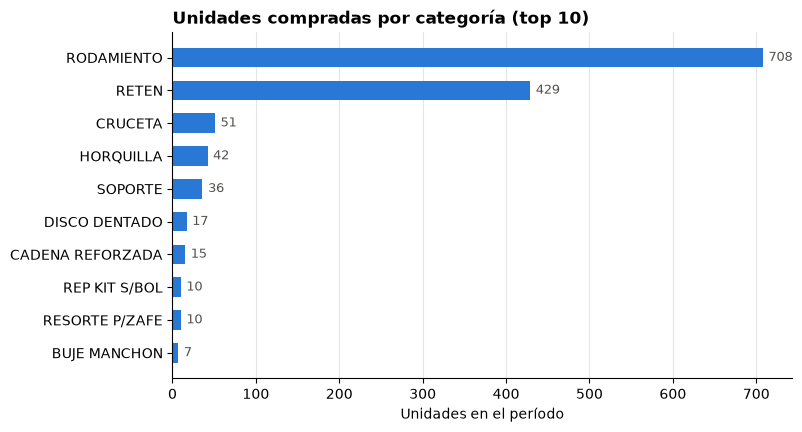

In [27]:
top_categorias = por_categoria.head(10).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.barh(top_categorias.index, top_categorias["unidades"], color=AZUL, height=0.6)
ax.bar_label(barras, fmt="%.0f", padding=4, fontsize=9, color="#52514e")
ax.set_title("Unidades compradas por categoría (top 10)")
ax.set_xlabel("Unidades en el período")
ax.grid(axis="y", visible=False)
plt.show()

## 8. El "ritmo" de compra de los repuestos más frecuentes

Cada punto es una compra; el tamaño del punto es la cantidad. Así se ve a simple vista si un repuesto se compra con regularidad (puntos espaciados parejo) o de forma esporádica.

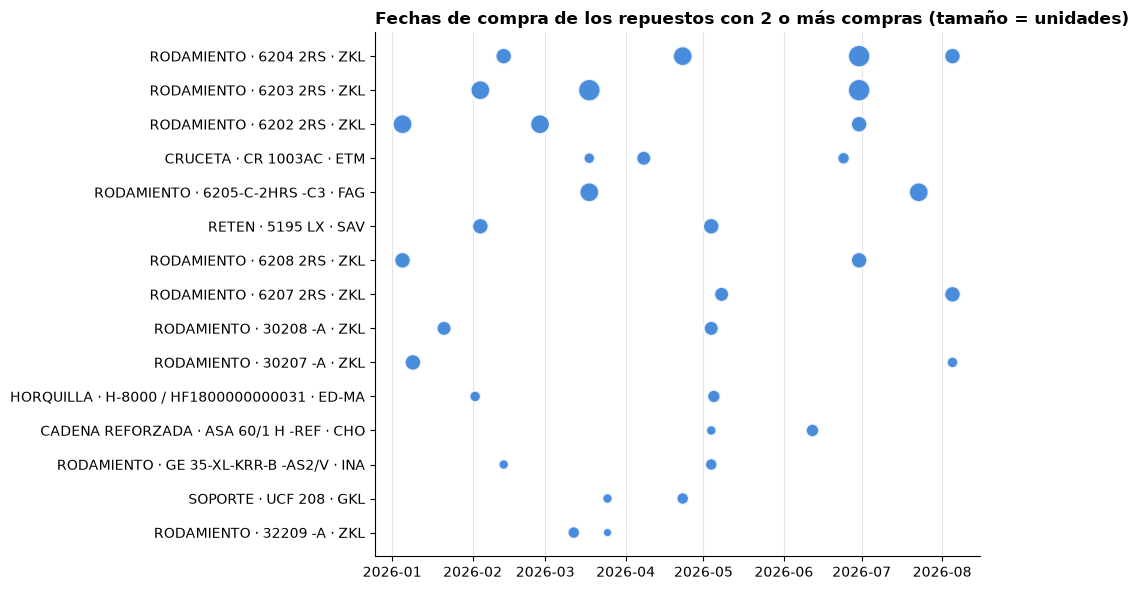

In [28]:
frecuentes = por_rep[por_rep["n_compras"] >= 2].sort_values(["n_compras", "unidades"], ascending=False)
ids = frecuentes["repuesto_id"].head(15).tolist()
puntos = movs[movs["repuesto_id"].isin(ids)]
orden_y = {rid: i for i, rid in enumerate(reversed(ids))}

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(puntos["fecha"], puntos["repuesto_id"].map(orden_y),
           s=puntos["cantidad"] * 12 + 20, color=AZUL, alpha=0.85,
           edgecolor="white", linewidth=1.5)
ax.set_yticks(list(orden_y.values()))
ax.set_yticklabels(frecuentes.set_index("repuesto_id").loc[list(reversed(ids)), "etiqueta"])
ax.set_title("Fechas de compra de los repuestos con 2 o más compras (tamaño = unidades)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [29]:
frecuentes[["etiqueta", "n_compras", "dias_entre_compras", "unidades", "uso_mensual_estimado"]].head(15)

,etiqueta,n_compras,dias_entre_compras,unidades,uso_mensual_estimado
52,RODAMIENTO · 6204 2RS · ZKL,4,57.67,55.00,7.90
45,RODAMIENTO · 6203 2RS · ZKL,3,73.00,55.00,7.90
64,RODAMIENTO · 6202 2RS · ZKL,3,88.00,40.00,5.74
82,CRUCETA · CR 1003AC · ETM,3,49.00,17.00,2.44
80,RODAMIENTO · 6205-C-2HRS -C3 · FAG,2,127.00,30.00,4.31
41,RETEN · 5195 LX · SAV,2,89.00,20.00,2.87
158,RODAMIENTO · 6208 2RS · ZKL,2,176.00,20.00,2.87
129,RODAMIENTO · 6207 2RS · ZKL,2,89.00,18.00,2.58
33,RODAMIENTO · 30208 -A · ZKL,2,103.00,16.00,2.30
25,RODAMIENTO · 30207 -A · ZKL,2,208.00,14.00,2.01


## 9. Conclusiones (con los datos de la carga inicial, enero–agosto 2026)

1. **Tu intuición se confirma en los datos:** el uso estimado varía muchísimo entre repuestos. Con 5 unidades, los rodamientos más usados (6202, 6203, 6204 2RS) cubren **menos de un mes**, mientras que la mitad de los repuestos cubriría **más de medio año**. **Por eso un único stock mínimo para todos no sirve**: los umbrales tienen que depender del uso de cada repuesto.
2. **La concentración está en las categorías, no en unos pocos repuestos:** rodamientos y retenes suman más del 80% de las unidades compradas. Pero **dentro** de esas categorías el movimiento está bastante repartido: hace falta casi la **mitad** de los repuestos para llegar al 80% (en un Pareto "clásico" serían alrededor del 20%). Por eso el análisis ABC por unidades no alcanza a separar bien los grupos; con precios (valor en pesos) probablemente sí.
3. **Más del 90% de los repuestos se compró una sola vez** y solo 4 se compraron 3 o más veces. Para ellos todavía no se puede estimar un ritmo confiable; solo sabemos que en 7 meses no hizo falta volver a comprarlos.
4. **Todo lo anterior es una aproximación basada en compras**, porque la base no tiene egresos. La compra no es el uso: se compra por lotes, por precio o "por las dudas".

### Qué haría falta para pasar de "aproximación" a "medición"
- **Registrar los EGRESOS** (cada vez que se saca un repuesto del stock para usarlo). Con eso, el uso mensual se calcula directamente.
- **Completar las especificaciones** de los repuestos de Iriondo, si hace falta (hoy se buscan en la base del proveedor con el código).
- **Revisar las unidades de medida** (cadenas) y los **posibles duplicados** de la sección 2.
- Con el uso real y el **tiempo de entrega** de cada proveedor, el **punto de reorden** se calcula, por ejemplo, como:
  $$\text{punto de reorden} = \text{uso diario} \times \text{días de entrega} + \text{stock de seguridad}$$

### 🧠 Preguntas para cerrar (para vos)
1. ¿Qué clase ABC y qué frecuencia tiene el repuesto que más usa el taller según tu experiencia? ¿Coincide con lo que muestran los datos?
2. Si tuvieras que definir **dos o tres reglas** de stock mínimo (una por grupo), ¿cómo serían?
3. ¿Qué información tendría que pedir la pantalla de "registrar egreso" para que este análisis se pueda repetir con datos reales?

In [30]:
# Cerrar la conexión a la base cuando terminamos
conexion.close()

---
### Fuentes
- *POO – Cuestiones sobre el manejo de datos* (clase del 07/09/2026, carpeta Teoría): representación, valores faltantes, curación y reproducibilidad.
- Documentación oficial de pandas — *Intro to data structures*, `groupby`, `merge`, `crosstab`: https://pandas.pydata.org/docs/user_guide/
- Documentación oficial de Python — módulo `sqlite3` (conexión de solo lectura con URI): https://docs.python.org/3/library/sqlite3.html
- Documentación de SQLite sobre `NULL`: https://www.sqlite.org/nulls.html
- Silver, E. A., Pyke, D. F. y Thomas, D. J. (2017). *Inventory and Production Management in Supply Chains* (4.ª ed.). CRC Press. — Clasificación ABC y punto de reorden.